# Notebook 05 — User-Level Features, Segmentation & Audience Exports

### 🎯 Objective

Roll up impression-level journeys into **user-level features**, discover **customer segments** via clustering, and export **ready-to-activate audiences** for BI / targeting.

This notebook answers:

* “What does each user’s journey look like over time?”
* “Which campaign mixes do different user groups respond to?”
* “How can I export segments for activation and reporting?”

---

## 📦 Inputs & Key Dependencies

* `../data/processed/journeys_all.parquet` — journeys (0/1 conversion), including:

  * `uid, campaign_seq, click_seq, cost_seq, time_since_last_click_seq, conversion` (or `conversion_id/conv_time`)
* (No external mapping required; this notebook is self-contained.)

---

## 🧱 What this notebook does

### A) Build user-level features

1. **Coerce sequences** to proper Python lists (robust to strings/arrays).
2. **Ensure conversion label** (fallback from `conversion_id`/`conv_time` when needed).
3. **Per-journey features** (then aggregated to user):

   * Impressions, clicks, spend, conversion.
   * Path stats: average path length, average unique campaigns per journey.
4. **User-level aggregates** (per `uid`):

   * `num_journeys, total_impr, total_clicks, total_spend, total_conv`
   * `avg_path_len, avg_unique_camps`
   * Rates: `ctr = total_clicks / total_impr`,
     `conv_rate_per_journey = total_conv / num_journeys`,
     `spend_per_journey = total_spend / num_journeys`
   * All rate calcs are **safe-divided** (0 when denominator is 0).

### B) Campaign-mix features (Top-K, memory-safe)

5. **Discover Top-K campaigns** globally from a sample (`SAMPLE_FRAC=5%`, capped at 5M rows) without exploding the full table.
6. **Per-journey counts for Top-K** campaigns (no large explode), then sum to user level and convert to **fractions of total impressions**.
7. **Downcast dtypes** to keep memory low.

### C) Clustering — exploratory (sample) → full scale (all users)

8. **Exploratory clustering** on ~100k users:

   * Scale features.
   * Try `k ∈ {3,4,5,6,7}` and pick **best silhouette**.
   * PCA scatter plot + quick cluster profiles.
   * **Result here**: `k=7` chosen (sample silhouette ≈ **0.334**).
9. **Full-scale clustering** with MiniBatchKMeans on **all users**:

   * Scale all features again (fresh scaler).
   * Fit MiniBatchKMeans with `k=7` (from exploratory step).
   * Sampled silhouette on full set ≈ **0.392** (indicates decent separation).
   * Save cluster assignments and profiles.

### D) Human-friendly labeling & mix insights

10. **Heuristic cluster labels**, based on unscaled centroids vs overall distribution:

    * e.g., “High-value repeat converters”, “Single-campaign heavy (…)", “Mixed behavior”, etc.
11. **Top campaign mix per cluster**: ranks the **Top-N campaigns** that define each cluster’s media exposure mix.

### E) Audience exports for activation

12. **Audience table**: `uid → (cluster_id, cluster_label)`.
13. **Per-cluster UID CSVs** for quick uploads to ad platforms.

---

## ⚙️ Parameters (tunable)

* `TOPK = 8` — number of campaigns to include in campaign-mix features.
* `SAMPLE_FRAC = 0.05` — sampling fraction to find Top-K campaigns.
* `MAX_ROWS_FOR_TOPK = 5_000_000` — safety cap on sampling rows.
* Exploratory clustering: `N_SAMPLE = 100_000`, `Ks = [3,4,5,6,7]`.
* Full scale: MiniBatchKMeans with `batch_size=10_000`, `max_iter=200`.

---

## 🗂️ Outputs

### BI-ready data

* `../artifacts/bi_exports/customer_clusters.csv`
  `uid, cluster_kmeans` + all feature columns used for clustering
* `../artifacts/bi_exports/cluster_profiles.csv`
  Mean feature values per cluster + user counts
* `../artifacts/bi_exports/customer_clusters_labeled.csv`
  `uid, cluster_kmeans, cluster_label` (human-friendly)
* `../artifacts/bi_exports/cluster_profiles_labeled.csv`
  Profiles with `cluster_label`
* `../artifacts/bi_exports/cluster_centroids_unscaled.csv`
  Unscaled centroids for interpretability (same columns as features)
* `../artifacts/bi_exports/cluster_top_campaign_mix.csv`
  Top-N campaign mix per cluster (mean share)
* `../artifacts/bi_exports/user_cluster_membership.csv`
  Single file for audience activation: `uid, cluster_kmeans, cluster_label`
* `../artifacts/bi_exports/user_clusters_split/cluster_{k}__{label}.csv`
  Per-cluster UID lists (one file per cluster)

### Models / scalers (for reuse)

* `../artifacts/models/cluster_scaler.joblib` — StandardScaler fit on **all** users
* `../artifacts/models/cluster_model_mbk.joblib` — MiniBatchKMeans (k=7)

### Visuals (rendered inline)

* PCA scatter of users colored by cluster.
* Bar charts of cluster-level means (e.g., `total_spend`, `total_conv`, `ctr`, etc.).

---

## 📈 Example results (from this run)

* **Users processed:** ~6.14M
* **Chosen k (exploratory):** 7 (silhouette ≈ 0.334 on sample)
* **Full-scale silhouette (sampled):** ≈ 0.392
* **Labels (examples):**

  * “High-value repeat converters”
  * “Single-campaign heavy (30801593)” / “Single-campaign heavy (17686799)”
  * “Mixed behavior”

These are **heuristic labels**—intended to be readable and can be customized.

---

## 🧠 How to read/act on the outputs

* **Customer_clusters(_labeled).csv**
  Use to push **inclusion/exclusion audiences** (e.g., “High-value repeat converters” to loyalty, “Single-campaign heavy” to creative tests, “Mixed behavior” to prospecting, etc.).

* **Cluster_profiles(_labeled).csv**
  BI table for **segment sizing** and **KPI benchmarks** (average spend, conversions, CTR, journey length).

* **Cluster_top_campaign_mix.csv**
  For **media planners** to see **which campaigns define each cluster**—helps decide where to increase/decrease frequency, change sequencing, or tailor creative.

---

## 🔍 Data & quality safeguards

* Robust list coercion (`campaign_seq`, `click_seq`, `cost_seq`, `time_since_last_click_seq`).
* **Safe divisions** to avoid NaNs/inf.
* **Downcasting** to keep memory reasonable.
* Top-K discovery uses a **sample** (fast, stable) and **no full-table explode**.
* Clustering uses **scaled** features and **MiniBatchKMeans** for scale.

---

## 🔌 How this fits the pipeline
1. **Notebook 01 — Data Preprocessing & EDA**
   Prepare impression-level data, KPIs, and Parquet artifacts.
2. **Notebook 02 — Build User Journeys**  
   Convert impressions → ordered user journeys with sequences.
3. **Notebook 03 — Attribution & Modeling (3a–3c)**  
   - **03a — Heuristic Attribution:** First/Last/Linear/Time-decay over journeys.  
   - **03b — Journey Conversion Modeling:** Logistic Regression & XGBoost with calibration + SHAP.  
   - **03c — Shapley Attribution (Monte Carlo):** Model-based credit per campaign.
4. **Notebook 04 — Attribution Rollups, ROI & Rule-vs-Model Comparison**   
   Consolidate attributions, compute ROI, compare methods.
5. **Notebook 05 — Customer Segmentation & Audience Exports** (This)   
   KMeans segmentation, campaign-mix profiles, and BI exports.
6. **Notebook 06 — Budget Reallocation Simulator (Upcoming)**  
   What-if scenarios using attributed ROI and constraints.*
   
   
---

## ✅ Repro steps (quick)

1. Ensure `../data/processed/journeys_all.parquet` exists (from Notebook 02).
2. Run the notebook end-to-end.
3. Pick up cluster artifacts in `../artifacts/bi_exports/` and models in `../artifacts/models/`.

---

## 📝 Notes & extensions (optional)

* Adjust `TOPK` if you want more/less campaign-mix detail.
* Swap KMeans for **HDBSCAN** or **Gaussian Mixtures** if you want soft memberships.
* Add **recency features** (e.g., days since last touch) to improve segment fidelity.
* Enrich labels with business metadata (e.g., map campaign IDs → names/channels for friendlier cluster names).

---

A) Load journeys & build customer features

In [3]:
import os, ast, numpy as np, pandas as pd

os.makedirs("../artifacts/bi_exports", exist_ok=True)

J = pd.read_parquet("../data/processed/journeys_all.parquet")

def to_pylist(x):
    if isinstance(x, list): return x
    if isinstance(x, (np.ndarray, pd.Series)): return x.tolist()
    if isinstance(x, str) and x.strip().startswith('[') and x.strip().endswith(']'):
        try: return ast.literal_eval(x)
        except Exception: return []
    if x is None or (isinstance(x, float) and pd.isna(x)) or x == "": return []
    return [x]

for c in ["campaign_seq","click_seq","cost_seq","time_since_last_click_seq"]:
    if c in J.columns:
        J[c] = J[c].apply(to_pylist)

# Ensure a 0/1 conversion column exists
if "conversion" not in J.columns:
    if "conversion_id" in J.columns:
        J["conversion"] = (J["conversion_id"] != -1).astype(int)
    elif "conv_time" in J.columns:
        J["conversion"] = (J["conv_time"].fillna(-1) >= 0).astype(int)
    else:
        J["conversion"] = 0

# Per-journey derived counts
journey_feats = pd.DataFrame({
    "uid": J["uid"],
    "impressions": J["campaign_seq"].apply(len),
    "clicks": J["click_seq"].apply(lambda x: int(np.sum(x)) if len(x) else 0),
    "spend": J["cost_seq"].apply(lambda x: float(np.sum(x)) if len(x) else 0.0),
    "conversion": J["conversion"].astype(int),
    "unique_camps_in_journey": J["campaign_seq"].apply(lambda x: len(set(x)))
})

# Aggregate to user level
user_aggr = (journey_feats
             .groupby("uid", as_index=False)
             .agg(
                 num_journeys = ("uid", "size"),
                 total_impr   = ("impressions", "sum"),
                 total_clicks = ("clicks", "sum"),
                 total_spend  = ("spend", "sum"),
                 total_conv   = ("conversion", "sum"),
                 avg_path_len = ("impressions", "mean"),
                 avg_unique_camps = ("unique_camps_in_journey", "mean")
             ))

# Rates (careful with zero division)
user_aggr["ctr"] = np.where(user_aggr["total_impr"]>0,
                            user_aggr["total_clicks"]/user_aggr["total_impr"], 0.0)
user_aggr["conv_rate_per_journey"] = np.where(user_aggr["num_journeys"]>0,
                                              user_aggr["total_conv"]/user_aggr["num_journeys"], 0.0)
user_aggr["spend_per_journey"] = np.where(user_aggr["num_journeys"]>0,
                                          user_aggr["total_spend"]/user_aggr["num_journeys"], 0.0)

print("Users:", len(user_aggr))
user_aggr.head()


Users: 6142256


,uid,num_journeys,total_impr,total_clicks,total_spend,total_conv,avg_path_len,avg_unique_camps,ctr,conv_rate_per_journey,spend_per_journey
0,10000,1,1,0,0.000032,0,1.0,1.0,0.0,0.0,0.000032
1,1000000,1,2,0,0.000020,0,2.0,1.0,0.0,0.0,0.000020
2,10000001,1,1,0,0.000362,0,1.0,1.0,0.0,0.0,0.000362
3,10000004,1,5,1,0.000200,0,5.0,2.0,0.2,0.0,0.000200
4,10000006,1,4,0,0.000659,0,4.0,2.0,0.0,0.0,0.000659


B) Campaign-mix features (Top-K) — memory optimized

In [5]:
import numpy as np
import pandas as pd


TOPK = 8                 # number of campaigns to include in the mix
SAMPLE_FRAC = 0.05       # fraction of journeys to use for top-k discovery
MAX_ROWS_FOR_TOPK = 5_000_000  # hard cap on rows for top-k sampling


# Ensure list-like
def to_pylist(x):
    if isinstance(x, list): return x
    if isinstance(x, (np.ndarray, pd.Series)): return x.tolist()
    if isinstance(x, str) and x.strip().startswith('[') and x.strip().endswith(']'):
        import ast
        try: return ast.literal_eval(x)
        except Exception: return []
    if x is None or (isinstance(x, float) and pd.isna(x)) or x == "": return []
    return [x]

if "campaign_seq" in J.columns:
    J["campaign_seq"] = J["campaign_seq"].apply(to_pylist)


# Find Top-K campaigns on a small sample

if SAMPLE_FRAC < 1.0:
    J_topk_src = J.sample(frac=SAMPLE_FRAC, random_state=42)
else:
    J_topk_src = J

# extra cap to protect memory on very large data
if len(J_topk_src) > MAX_ROWS_FOR_TOPK:
    J_topk_src = J_topk_src.head(MAX_ROWS_FOR_TOPK)

# Count campaign frequency from the sample without full explode
from collections import Counter
camp_counter = Counter()
for seq in J_topk_src["campaign_seq"]:
    # update counts by iterating the seq (no explode)
    for c in seq:
        camp_counter[str(c)] += 1

top_campaigns = [cid for cid, _ in camp_counter.most_common(TOPK)]
top_set = set(top_campaigns)
print(f"Top-{TOPK} campaigns (sample-based):", top_campaigns)


# Compute per-journey counts for each of the Top-K


def count_in_seq(seq, target):
    # count how many touches in seq belong to 'target' campaign id
    t = str(target)
    # micro-optimized loop (faster than seq.count on mixed types)
    c = 0
    for x in seq:
        if str(x) == t:
            c += 1
    return c

# Build a compact DataFrame with uid and per-top-campaign counts
journey_mix = pd.DataFrame({"uid": J["uid"]})
for cid in top_campaigns:
    col = f"mix_camp_{cid}"
    journey_mix[col] = J["campaign_seq"].apply(lambda s, cid=cid: count_in_seq(s, cid)).astype("int32")


# Aggregate per user (sum across journeys)

mix_user = (journey_mix
            .groupby("uid", as_index=False)
            .sum())

# Convert counts → fractions by total_impr
#     and downcast to save memory

mix_user = mix_user.merge(user_aggr[["uid","total_impr"]], on="uid", how="left")
for cid in top_campaigns:
    col = f"mix_camp_{cid}"
    # fraction of impressions for this campaign
    mix_user[col] = np.where(mix_user["total_impr"] > 0,
                             mix_user[col] / mix_user["total_impr"],
                             0.0).astype("float32")

mix_user = mix_user.drop(columns=["total_impr"])

# Merge back into user_aggr → users_full

users_full = user_aggr.merge(mix_user, on="uid", how="left").fillna(0.0)

# Downcast main numeric columns for memory
for c in users_full.columns:
    if c == "uid": 
        continue
    if users_full[c].dtype == "float64":
        users_full[c] = users_full[c].astype("float32")
    if users_full[c].dtype == "int64":
        users_full[c] = users_full[c].astype("int32")

print("Final user feature table:", users_full.shape)
users_full.head()


Top-8 campaigns (sample-based): ['10341182', '30801593', '17686799', '15398570', '5061834', '15184511', '29427842', '18975823']
Final user feature table: (6142256, 19)


,uid,num_journeys,total_impr,total_clicks,total_spend,total_conv,avg_path_len,avg_unique_camps,ctr,conv_rate_per_journey,spend_per_journey,mix_camp_10341182,mix_camp_30801593,mix_camp_17686799,mix_camp_15398570,mix_camp_5061834,mix_camp_15184511,mix_camp_29427842,mix_camp_18975823
0,10000,1,1,0,0.000032,0,1.0,1.0,0.0,0.0,0.000032,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1000000,1,2,0,0.000020,0,2.0,1.0,0.0,0.0,0.000020,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,10000001,1,1,0,0.000362,0,1.0,1.0,0.0,0.0,0.000362,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,10000004,1,5,1,0.000200,0,5.0,2.0,0.2,0.0,0.000200,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,10000006,1,4,0,0.000659,0,4.0,2.0,0.0,0.0,0.000659,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


C1) Exploratory clustering (sample 100k + PCA plots)

Python(69177) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(69195) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


[Exploratory] k=3 silhouette=0.2803
[Exploratory] k=4 silhouette=0.2735
[Exploratory] k=5 silhouette=0.2953
[Exploratory] k=6 silhouette=0.3152
[Exploratory] k=7 silhouette=0.3338
[Exploratory] Chosen k=7 (silhouette=0.3338)


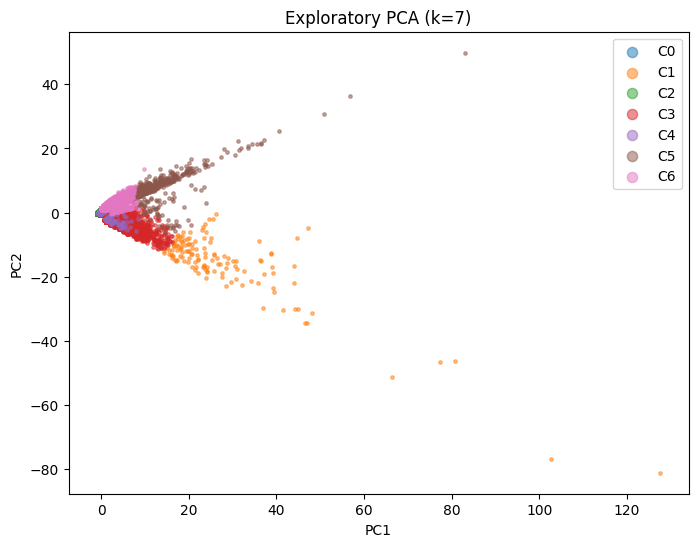

,cluster_kmeans_exp,num_journeys,total_impr,total_clicks,total_spend,total_conv,avg_path_len,avg_unique_camps,ctr,conv_rate_per_journey,spend_per_journey,mix_camp_10341182,mix_camp_30801593,mix_camp_17686799,mix_camp_15398570,mix_camp_5061834,mix_camp_15184511,mix_camp_29427842,mix_camp_18975823
0,0,1.000000,1.841584,1.388766,0.000472,0.000000,1.841584,1.124448,0.831947,0.000000,0.000472,0.023969,0.043526,0.016641,0.000136,0.014667,0.007470,0.012211,0.022801
1,1,20.526316,36.255639,25.443609,0.057851,19.857143,2.004108,1.157145,0.708820,0.957171,0.003573,0.039363,0.014540,0.002324,0.042731,0.020419,0.036720,0.028899,0.008792
2,2,1.000000,1.596288,0.073117,0.000170,0.000000,1.596288,1.112703,0.021867,0.000000,0.000170,0.020089,0.029100,0.027685,0.000159,0.024567,0.014808,0.014332,0.009480
3,3,2.598031,5.724213,2.859449,0.002873,2.008071,2.168043,1.230758,0.607439,0.765819,0.000910,0.043497,0.034718,0.011420,0.005811,0.019368,0.032434,0.014659,0.014821
4,4,1.074376,2.841477,0.897937,0.000689,0.097720,2.677775,1.251583,0.267106,0.042123,0.000588,0.011587,0.002254,0.000181,0.912827,0.000982,0.000422,0.000271,0.000155
5,5,1.299685,24.488959,14.977918,0.022081,0.312303,22.355352,2.166529,0.622513,0.077613,0.019507,0.028075,0.005397,0.026390,0.028383,0.019785,0.021788,0.023537,0.015333
6,6,1.010141,7.520519,2.648469,0.001819,0.010426,7.440053,2.298566,0.344116,0.005323,0.001796,0.024195,0.017750,0.028431,0.006637,0.019406,0.013135,0.016053,0.009377


In [8]:
# Exploratory clustering on a sample (≈100k)
import numpy as np, pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import os

os.makedirs("../artifacts/bi_exports", exist_ok=True)
os.makedirs("../artifacts/models", exist_ok=True)

# Feature set
base_cols = [
    "num_journeys","total_impr","total_clicks","total_spend","total_conv",
    "avg_path_len","avg_unique_camps","ctr","conv_rate_per_journey","spend_per_journey"
]
mix_cols  = [c for c in users_full.columns if c.startswith("mix_camp_")]
feat_cols = base_cols + mix_cols

# mSample ~100k users for exploration
N_SAMPLE = 100_000
sample = users_full.sample(n=min(N_SAMPLE, len(users_full)), random_state=42)
X_sample = sample[feat_cols].astype("float32").values

# Scale
scaler_exp = StandardScaler(with_mean=True, with_std=True)
X_sample_scaled = scaler_exp.fit_transform(X_sample)

# Try several k, pick best by silhouette 
Ks = [3,4,5,6,7]
best = {"k": None, "sil": -1, "labels": None, "model": None}
for k in Ks:
    km = KMeans(n_clusters=k, n_init="auto", random_state=42)
    labels = km.fit_predict(X_sample_scaled)
    sil = silhouette_score(X_sample_scaled, labels)
    print(f"[Exploratory] k={k} silhouette={sil:.4f}")
    if sil > best["sil"]:
        best.update({"k": k, "sil": sil, "labels": labels, "model": km})

print(f"[Exploratory] Chosen k={best['k']} (silhouette={best['sil']:.4f})")

sample["cluster_kmeans_exp"] = best["labels"]

# PCA for visualization
pca = PCA(n_components=2, random_state=42)
Xp = pca.fit_transform(X_sample_scaled)
plt.figure(figsize=(8,6))
for k in sorted(sample["cluster_kmeans_exp"].unique()):
    idx = (sample["cluster_kmeans_exp"] == k).values
    plt.scatter(Xp[idx,0], Xp[idx,1], s=6, alpha=0.5, label=f"C{k}")
plt.title(f"Exploratory PCA (k={best['k']})")
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.legend(markerscale=3)
plt.show()

# Quick cluster profiles (means on the sample)
profiles_exp = (sample[["cluster_kmeans_exp"] + feat_cols]
                .groupby("cluster_kmeans_exp", as_index=False)
                .mean()
                .sort_values("cluster_kmeans_exp"))
display(profiles_exp.head(10))

# Save exploratory artifacts
profiles_exp.to_csv("../artifacts/bi_exports/cluster_profiles_exploratory.csv", index=False)
sample[["uid","cluster_kmeans_exp"]].to_csv("../artifacts/bi_exports/customer_clusters_exploratory.csv", index=False)

# Keep the chosen k for the full-scale step below:
EXP_K = best["k"]


C2) Full-scale clustering (MiniBatchKMeans on all users)

In [11]:
# Full-scale clustering on ALL users with MiniBatchKMeans ---
from sklearn.cluster import MiniBatchKMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
import joblib

# Feature matrix for ALL users
X_all = users_full[feat_cols].astype("float32").values

# Scale on ALL users (fresh scaler for production)
scaler_full = StandardScaler(with_mean=True, with_std=True)
X_all_scaled = scaler_full.fit_transform(X_all)

# MiniBatchKMeans with k = EXP_K (chosen in C1)
k_final = int(EXP_K) if "EXP_K" in globals() and EXP_K is not None else 5
mbk = MiniBatchKMeans(
    n_clusters=k_final,
    random_state=42,
    batch_size=10_000,
    n_init="auto",
    max_iter=200
)
labels_all = mbk.fit_predict(X_all_scaled)
users_full["cluster_kmeans"] = labels_all

# Silhouette on a sample of the full set (for speed)
sil_sample = users_full.sample(n=min(200_000, len(users_full)), random_state=123)
X_s = scaler_full.transform(sil_sample[feat_cols].astype("float32").values)
sil = silhouette_score(X_s, sil_sample["cluster_kmeans"].values)
print(f"[Full-scale] k={k_final} silhouette (sampled) = {sil:.4f}")

#Cluster profiles (means) on ALL users
profiles_full = (users_full[["cluster_kmeans"] + feat_cols]
                 .groupby("cluster_kmeans", as_index=False)
                 .mean())
profiles_full["n_users"] = users_full.groupby("cluster_kmeans").size().values
profiles_full = profiles_full.sort_values("n_users", ascending=False)
display(profiles_full.head(10))

# Save outputs for BI/demo
out_users = "../artifacts/bi_exports/customer_clusters.csv"
out_prof  = "../artifacts/bi_exports/cluster_profiles.csv"
users_full_out = users_full[["uid","cluster_kmeans"] + feat_cols]
users_full_out.to_csv(out_users, index=False)
profiles_full.to_csv(out_prof, index=False)
print("Saved ->", out_users)
print("Saved ->", out_prof)

# Save model + scaler for reuse
joblib.dump(scaler_full, "../artifacts/models/cluster_scaler.joblib")
joblib.dump(mbk, "../artifacts/models/cluster_model_mbk.joblib")
print("Saved -> ../artifacts/models/cluster_scaler.joblib, cluster_model_mbk.joblib")


[Full-scale] k=7 silhouette (sampled) = 0.3920


,cluster_kmeans,num_journeys,total_impr,total_clicks,total_spend,total_conv,avg_path_len,avg_unique_camps,ctr,conv_rate_per_journey,spend_per_journey,mix_camp_10341182,mix_camp_30801593,mix_camp_17686799,mix_camp_15398570,mix_camp_5061834,mix_camp_15184511,mix_camp_29427842,mix_camp_18975823,n_users
4,4,1.000000,1.517855,0.071595,0.000161,0.000000,1.517855,1.000000,0.018329,0.000000,0.000161,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2620340
1,1,1.088804,2.010873,1.496016,0.000580,0.147077,1.869174,1.070275,0.840471,0.088539,0.000527,0.017979,0.001088,0.000492,0.000289,0.001397,0.007018,0.000968,0.016870,1559717
2,2,1.013439,3.094006,0.654876,0.000504,0.015438,3.063150,1.864631,0.196295,0.008300,0.000493,0.083735,0.004615,0.005312,0.002944,0.107674,0.050938,0.066829,0.042531,1150892
5,5,2.391621,13.298187,6.543907,0.007740,1.483282,9.988452,2.002122,0.495287,0.254521,0.004693,0.032546,0.008307,0.011886,0.009754,0.012759,0.021810,0.015432,0.012903,356028
0,0,1.049749,2.043761,0.747907,0.000111,0.068303,1.936782,1.149227,0.361409,0.032422,0.000099,0.000240,0.939602,0.000266,0.000173,0.000238,0.000122,0.000165,0.000143,189874
6,6,1.019272,2.253187,0.624784,0.000386,0.029549,2.216217,1.283283,0.255811,0.015881,0.000372,0.000886,0.001463,0.893437,0.000565,0.000307,0.000233,0.000241,0.000584,149178
3,3,1.094143,2.880243,0.928184,0.000773,0.116685,2.679604,1.243667,0.280182,0.043286,0.000621,0.009361,0.001484,0.000421,0.913797,0.000333,0.000298,0.000275,0.000580,116227


Saved -> ../artifacts/bi_exports/customer_clusters.csv
Saved -> ../artifacts/bi_exports/cluster_profiles.csv
Saved -> ../artifacts/models/cluster_scaler.joblib, cluster_model_mbk.joblib


Label clusters (human-friendly names) and save

In [13]:
import numpy as np
import pandas as pd
import os

os.makedirs("../artifacts/bi_exports", exist_ok=True)

# Unscaled cluster centroids (easier to read/threshold)
centroids_unscaled = pd.DataFrame(
    scaler_full.inverse_transform(mbk.cluster_centers_),
    columns=feat_cols
)
centroids_unscaled["cluster"] = range(mbk.n_clusters)

# Heuristic labeling rules (tweak thresholds as you like)
def label_cluster(row, df_all):
    q = df_all.quantile  # convenient
    if (row["total_conv"] >= q(0.75)["total_conv"]) and (row["total_spend"] >= q(0.75)["total_spend"]):
        return "High-value repeat converters"
    if (row["total_conv"] == 0) and (row["total_spend"] <= q(0.25)["total_spend"]) and (row["total_impr"] <= q(0.25)["total_impr"]):
        return "Low-value viewers"
    if (row["ctr"] >= q(0.75)["ctr"]) and (row["total_conv"] == 0):
        return "Clickers, not buyers"
    if (row["avg_path_len"] <= q(0.25)["avg_path_len"]) and (row["total_conv"] >= q(0.50)["total_conv"]):
        return "Quick-win converters"
    # Campaign-mix heavy segments (if one mix feature dominates)
    dominant_mix = [c for c in mix_cols if c in row.index]
    if dominant_mix:
        top_mix = pd.Series({c: row[c] for c in dominant_mix}).sort_values(ascending=False)
        if top_mix.iloc[0] > 0.5:  # >50% impressions from one campaign
            return f"Single-campaign heavy ({top_mix.index[0].replace('mix_camp_','')})"
    return "Mixed behavior"

# Apply labels using global distribution (centroids vs overall)
overall = users_full[feat_cols].astype(float)
centroids_unscaled["cluster_label"] = centroids_unscaled.apply(lambda r: label_cluster(r, overall), axis=1)

# Map labels back to users and profiles
label_map = dict(zip(centroids_unscaled["cluster"], centroids_unscaled["cluster_label"]))
users_full["cluster_label"] = users_full["cluster_kmeans"].map(label_map)

# Refresh profiles with labels & sizes
profiles_full = (users_full[["cluster_kmeans","cluster_label"] + feat_cols]
                 .groupby(["cluster_kmeans","cluster_label"], as_index=False)
                 .mean())
profiles_full["n_users"] = users_full.groupby(["cluster_kmeans","cluster_label"]).size().values
profiles_full = profiles_full.sort_values("n_users", ascending=False)

# Save labeled outputs
users_full[["uid","cluster_kmeans","cluster_label"]].to_csv("../artifacts/bi_exports/customer_clusters_labeled.csv", index=False)
profiles_full.to_csv("../artifacts/bi_exports/cluster_profiles_labeled.csv", index=False)
centroids_unscaled.to_csv("../artifacts/bi_exports/cluster_centroids_unscaled.csv", index=False)

print("Saved -> customer_clusters_labeled.csv, cluster_profiles_labeled.csv, cluster_centroids_unscaled.csv")
profiles_full.head(10)


Saved -> customer_clusters_labeled.csv, cluster_profiles_labeled.csv, cluster_centroids_unscaled.csv


,cluster_kmeans,cluster_label,num_journeys,total_impr,total_clicks,total_spend,total_conv,avg_path_len,avg_unique_camps,ctr,...,spend_per_journey,mix_camp_10341182,mix_camp_30801593,mix_camp_17686799,mix_camp_15398570,mix_camp_5061834,mix_camp_15184511,mix_camp_29427842,mix_camp_18975823,n_users
4,4,Mixed behavior,1.000000,1.517855,0.071595,0.000161,0.000000,1.517855,1.000000,0.018329,...,0.000161,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2620340
1,1,High-value repeat converters,1.088804,2.010873,1.496016,0.000580,0.147077,1.869174,1.070275,0.840471,...,0.000527,0.017979,0.001088,0.000492,0.000289,0.001397,0.007018,0.000968,0.016870,1559717
2,2,High-value repeat converters,1.013439,3.094006,0.654876,0.000504,0.015438,3.063150,1.864631,0.196295,...,0.000493,0.083735,0.004615,0.005312,0.002944,0.107674,0.050938,0.066829,0.042531,1150892
5,5,High-value repeat converters,2.391621,13.298187,6.543907,0.007740,1.483282,9.988452,2.002122,0.495287,...,0.004693,0.032546,0.008307,0.011886,0.009754,0.012759,0.021810,0.015432,0.012903,356028
0,0,Single-campaign heavy (30801593),1.049749,2.043761,0.747907,0.000111,0.068303,1.936782,1.149227,0.361409,...,0.000099,0.000240,0.939602,0.000266,0.000173,0.000238,0.000122,0.000165,0.000143,189874
6,6,Single-campaign heavy (17686799),1.019272,2.253187,0.624784,0.000386,0.029549,2.216217,1.283283,0.255811,...,0.000372,0.000886,0.001463,0.893437,0.000565,0.000307,0.000233,0.000241,0.000584,149178
3,3,High-value repeat converters,1.094143,2.880243,0.928184,0.000773,0.116685,2.679604,1.243667,0.280182,...,0.000621,0.009361,0.001484,0.000421,0.913797,0.000333,0.000298,0.000275,0.000580,116227


Label clusters (human-friendly names) and save

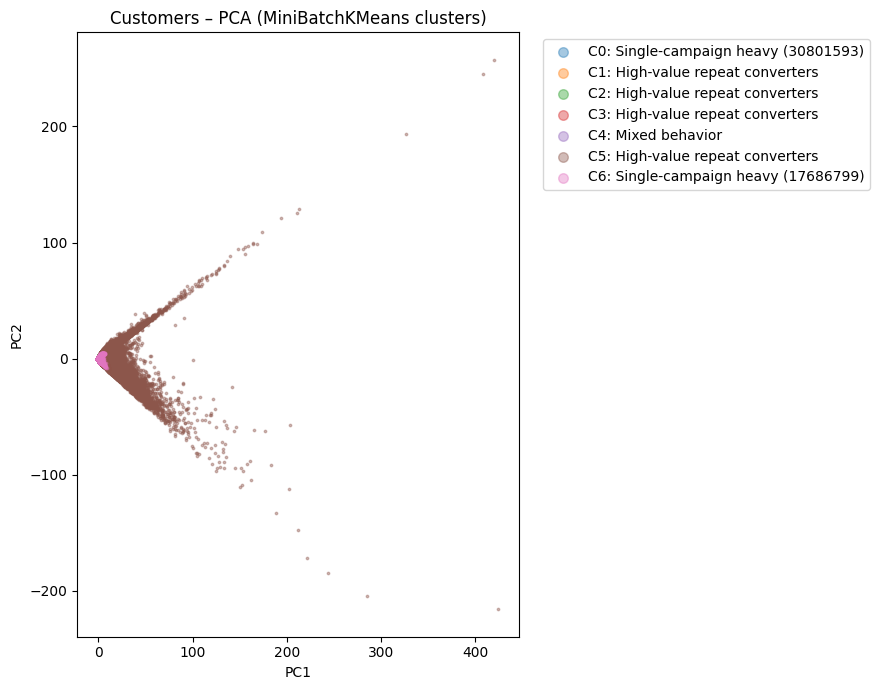

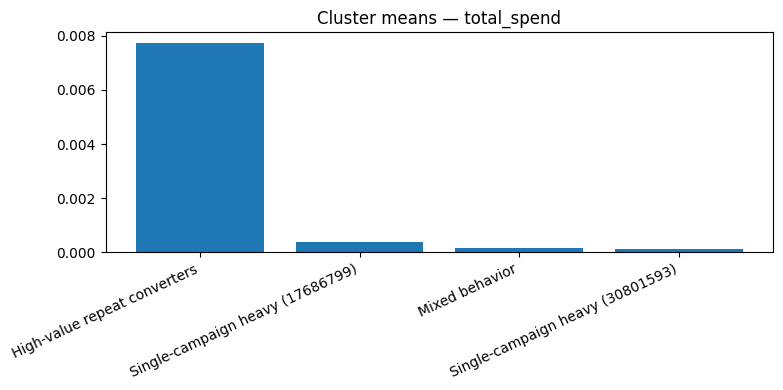

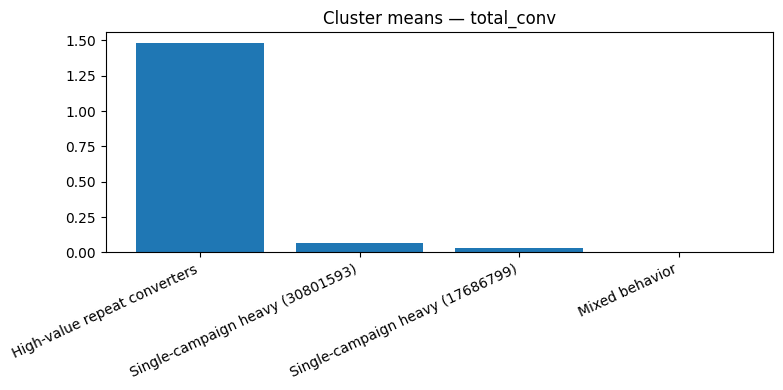

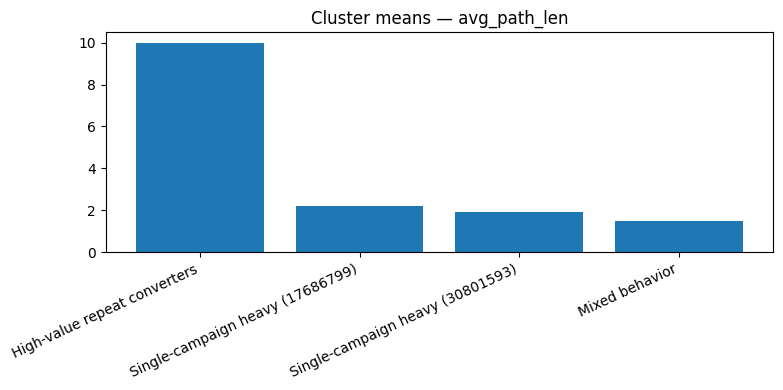

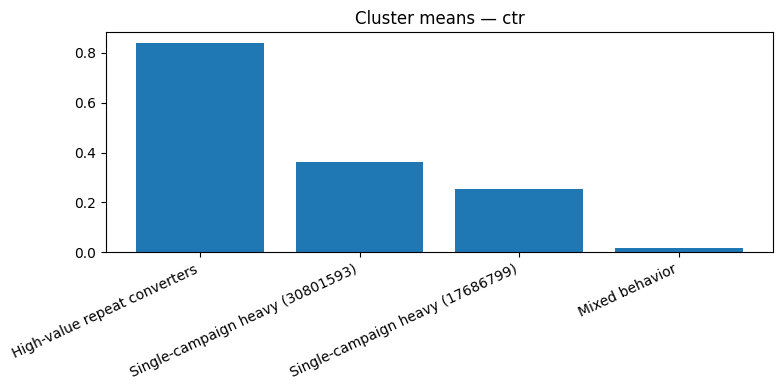

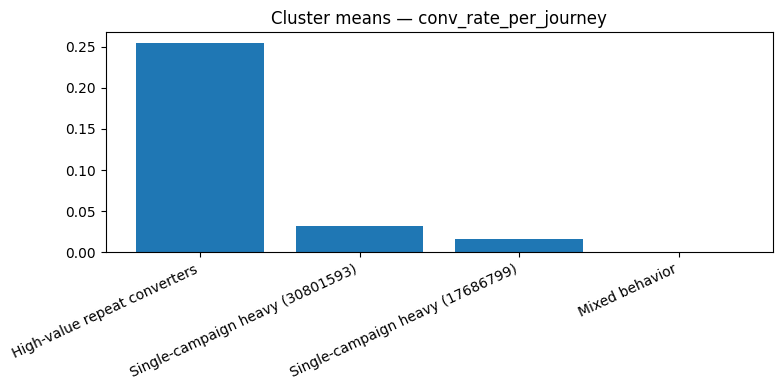

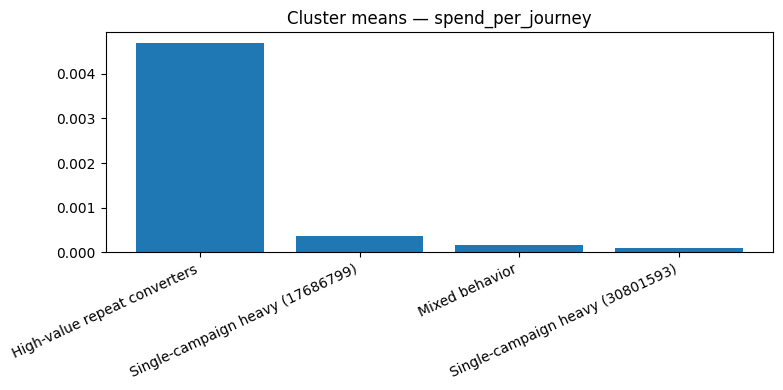

In [16]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Build matrix & labels
X_all_scaled = scaler_full.transform(users_full[feat_cols].astype("float32").values)
labels = users_full["cluster_kmeans"].values
names  = users_full["cluster_label"].values

# PCA to 2D
pca = PCA(n_components=2, random_state=42)
Xp = pca.fit_transform(X_all_scaled)

# PCA scatter with readable legend
plt.figure(figsize=(9,7))
for k in sorted(np.unique(labels)):
    idx = labels == k
    plt.scatter(Xp[idx,0], Xp[idx,1], s=3, alpha=0.4, label=f"C{k}: {label_map[k]}")
plt.title("Customers – PCA (MiniBatchKMeans clusters)")
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.legend(markerscale=4, bbox_to_anchor=(1.04, 1), loc="upper left")
plt.tight_layout()
plt.show()

# Bar plots for selected cluster-level means
sel_metrics = ["total_spend","total_conv","avg_path_len","ctr","conv_rate_per_journey","spend_per_journey"]
prof_m = profiles_full[["cluster_kmeans","cluster_label"] + sel_metrics].copy()

for metric in sel_metrics:
    plt.figure(figsize=(8,4))
    order = prof_m.sort_values(metric, ascending=False)
    plt.bar(order["cluster_label"], order[metric])
    plt.title(f"Cluster means — {metric}")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()


Channel (campaign) mix insights per cluster

In [19]:
import pandas as pd
import numpy as np

# Mix columns from earlier
mix_cols = [c for c in users_full.columns if c.startswith("mix_camp_")]
assert len(mix_cols) > 0, "No mix_camp_* columns found."

# Mean mix by cluster
mix_profile = (users_full[["cluster_kmeans","cluster_label"] + mix_cols]
               .groupby(["cluster_kmeans","cluster_label"], as_index=False)
               .mean())

# Melt to long form and rank within each cluster
mix_long = mix_profile.melt(id_vars=["cluster_kmeans","cluster_label"],
                            value_vars=mix_cols,
                            var_name="campaign_mix",
                            value_name="mean_fraction")
mix_long["campaign_id"] = mix_long["campaign_mix"].str.replace("mix_camp_","", regex=False)

# Top-N campaigns by mean share per cluster
TOPN = 5
top_mix_per_cluster = (mix_long
                       .sort_values(["cluster_kmeans","mean_fraction"], ascending=[True, False])
                       .groupby(["cluster_kmeans","cluster_label"])
                       .head(TOPN)
                       .reset_index(drop=True))

# Save & preview
top_mix_per_cluster.to_csv("../artifacts/bi_exports/cluster_top_campaign_mix.csv", index=False)
print("Saved -> cluster_top_campaign_mix.csv")
top_mix_per_cluster.head(20)


Saved -> cluster_top_campaign_mix.csv


,cluster_kmeans,cluster_label,campaign_mix,mean_fraction,campaign_id
0,0,Single-campaign heavy (30801593),mix_camp_30801593,0.939602,30801593
1,0,Single-campaign heavy (30801593),mix_camp_17686799,0.000266,17686799
2,0,Single-campaign heavy (30801593),mix_camp_10341182,0.000240,10341182
3,0,Single-campaign heavy (30801593),mix_camp_5061834,0.000238,5061834
4,0,Single-campaign heavy (30801593),mix_camp_15398570,0.000173,15398570
5,1,High-value repeat converters,mix_camp_10341182,0.017979,10341182
6,1,High-value repeat converters,mix_camp_18975823,0.016870,18975823
7,1,High-value repeat converters,mix_camp_15184511,0.007018,15184511
8,1,High-value repeat converters,mix_camp_5061834,0.001397,5061834
9,1,High-value repeat converters,mix_camp_30801593,0.001088,30801593


In [21]:
import pandas as pd
import os

# Minimal audience file: uid → cluster ID + human label
audience = users_full[["uid", "cluster_kmeans", "cluster_label"]].copy()

# Drop accidental duplicates
audience = audience.drop_duplicates(subset=["uid"]).reset_index(drop=True)

# Save to BI/activation folder
os.makedirs("../artifacts/bi_exports", exist_ok=True)
audience_path = "../artifacts/bi_exports/user_cluster_membership.csv"
audience.to_csv(audience_path, index=False)
print("Saved ->", audience_path)

# Quick QA: cluster sizes
sizes = (audience
         .groupby(["cluster_kmeans","cluster_label"], as_index=False)
         .size()
         .sort_values("size", ascending=False))
display(sizes.head(20))

# export one CSV per cluster for easy uploads to ad platforms
per_cluster_dir = "../artifacts/bi_exports/user_clusters_split"
os.makedirs(per_cluster_dir, exist_ok=True)

for (cid, label), g in audience.groupby(["cluster_kmeans", "cluster_label"]):
    safe_label = "".join(ch if ch.isalnum() or ch in "-_ " else "_" for ch in str(label))
    out = os.path.join(per_cluster_dir, f"cluster_{cid}__{safe_label}.csv")
    g[["uid"]].to_csv(out, index=False)
print(f"Also wrote per-cluster uid lists to: {per_cluster_dir}")


Saved -> ../artifacts/bi_exports/user_cluster_membership.csv


,cluster_kmeans,cluster_label,size
4,4,Mixed behavior,2620340
1,1,High-value repeat converters,1559717
2,2,High-value repeat converters,1150892
5,5,High-value repeat converters,356028
0,0,Single-campaign heavy (30801593),189874
6,6,Single-campaign heavy (17686799),149178
3,3,High-value repeat converters,116227


Also wrote per-cluster uid lists to: ../artifacts/bi_exports/user_clusters_split


In [35]:
aud = pd.read_csv("../artifacts/bi_exports/user_cluster_membership.csv")
print(aud.shape)
print(aud.head())            # shows uid, cluster_kmeans, cluster_label

(6142256, 3)
        uid  cluster_kmeans                 cluster_label
0     10000               4                Mixed behavior
1   1000000               4                Mixed behavior
2  10000001               4                Mixed behavior
3  10000004               2  High-value repeat converters
4  10000006               2  High-value repeat converters
